# Tracking shuffled objects: first-error detection

Cache-only analysis of the 100 sampled BIG-Bench Mistake traces (seed 42). Scores are evaluated per step: only the annotated first error is positive; every other step, including later steps, is negative. The LLM judge instead predicts one error location per trace, so its binary F1 is not directly comparable.


In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from scipy.stats import mannwhitneyu
from sklearn.metrics import roc_auc_score, roc_curve

from experiment_setup import dc_pmi, llm_critic
from experiment_setup.benchmarks import Example, ROOT, sample_tasks, solution_for

BENCHMARK, TASK = 'BIG-Bench-Mistake', 'tracking_shuffled_objects'
MODELS = {'4B': 'Qwen/Qwen3.5-4B', '9B': 'Qwen/Qwen3.5-9B', '27B': 'Qwen/Qwen3.5-27B'}
CACHE = Path('final-cache')
task_examples = []
with (ROOT / 'BIG-Bench-Mistake' / f'{TASK}.jsonl').open() as file:
    for i, line in enumerate(file):
        row = json.loads(line)
        task_examples.append(Example(BENCHMARK, TASK, str(i), row['input'], tuple(row['steps']),
                                     row['mistake_index'], row['target']))
examples = sample_tasks({(BENCHMARK, TASK): task_examples}, size=100, seed=42)
assert len(examples) == 100
assert len({e.uid for e in examples}) == len(examples)

scores_by_model = {}
judge_by_model = {}
for model, model_id in MODELS.items():
    scores_by_model[model] = dc_pmi.load_run(
        examples, model_id=model_id,
        cache_path=CACHE / f'dc_pmi_qwen35_{model.lower()}_arm.sqlite',
    )
    judge_by_model[model] = llm_critic.load_run(
        examples, model_id=model_id, thinking=False,
        cache_path=CACHE / f'llm_judge_qwen35_{model.lower()}_arm.sqlite',
    )
    assert scores_by_model[model].uid.nunique() == len(judge_by_model[model]) == len(examples)
print(f'{len(examples)} traces; {sum(e.label is not None for e in examples)} with an annotated error')


100 traces; 83 with an annotated error


## Full example trace


In [2]:
example = next(e for e in examples if e.label is not None)
print(f'UID: {example.uid}\nQuestion:\n{example.question}\n')
print(f'Complete solution:\n{solution_for(example)}\n')
print(f'Ground-truth answer: {example.ground_truth_answer}')
print(f'Annotated first error: Step {example.label + 1}\n')
trace = scores_by_model['27B'].loc[
    scores_by_model['27B'].uid == example.uid,
    ['step', 'first_error', 'dc_pmi_question_ablation', 'perplexity'],
].copy()
trace['step'] += 1
trace['negative_question_ablated_dc_pmi'] = -trace.pop('dc_pmi_question_ablation')
display(trace.to_string(index=False))
judge_trace = judge_by_model['27B'].set_index('uid').loc[example.uid]
print(f'\n27B judge prediction: {"NONE" if pd.isna(judge_trace.prediction) else f"Step {int(judge_trace.prediction) + 1}"}')
print(f'Parse error: {judge_trace.parse_error}\nFull judge transcript:\n{judge_trace.transcript}')


UID: 98
Question:
Alice, Bob, Claire, Dave, and Eve are playing a game. At the start of the game, they are each holding a ball: Alice has a green ball, Bob has a purple ball, Claire has a black ball, Dave has a blue ball, and Eve has a red ball.
As the game progresses, pairs of players trade balls. First, Dave and Eve swap balls. Then, Bob and Alice swap balls. Then, Eve and Claire swap balls. Then, Bob and Dave swap balls. Finally, Dave and Claire swap balls. At the end of the game, Claire has the
Options:
(A) green ball.
(B) purple ball.
(C) black ball.
(D) blue ball.
(E) red ball.

Complete solution:
Step 1: A: green, B: purple, C: black, D: blue, E: red
Step 2: D: red, E: blue, B: green, A: purple, C: black
Step 3: D: red, E: black, B: green, A: purple, C: blue
Step 4: D: red, E: black, B: purple, A: green, C: blue
Step 5: D: red, E: black, B: purple, A: green, C: blue
Step 6: So the answer is (D)

Ground-truth answer: (A)
Annotated first error: Step 2



' step  first_error  perplexity  negative_question_ablated_dc_pmi\n    1        False    2.630110                        -20.577493\n    2         True    2.000302                         -0.000678\n    3        False    1.104017                         -7.310947\n    4        False    1.337952                          2.408126\n    5        False    1.165259                          1.397684\n    6        False    3.678569                         -1.718491'


27B judge prediction: Step 2
Parse error: None
Full judge transcript:
<|im_start|>user
You are given a step-by-step solution to a reasoning problem. If the solution contains any mathematical, logical or conceptual errors, identify the FIRST incorrect step. Be careful: even if the final answer is correct, the solution path may contain errors. Problem:
Alice, Bob, Claire, Dave, and Eve are playing a game. At the start of the game, they are each holding a ball: Alice has a green ball, Bob has a purple ball, Claire has a black ball, Dave has a blue ball, and Eve has a red ball.
As the game progresses, pairs of players trade balls. First, Dave and Eve swap balls. Then, Bob and Alice swap balls. Then, Eve and Claire swap balls. Then, Bob and Dave swap balls. Finally, Dave and Claire swap balls. At the end of the game, Claire has the
Options:
(A) green ball.
(B) purple ball.
(C) black ball.
(D) blue ball.
(E) red ball.

Solution:
Step 1: A: green, B: purple, C: black, D: blue, E: red
Step 2:

## Step-level ROC and statistics

Negative question-ablated DC-PMI treats lower raw scores as stronger error evidence. For DC-PMI only, the one-sided Mann–Whitney U test asks whether negated scores at first-error steps exceed those at **all** other steps; U is computed with the first-error group first. Perplexity has no significance test. F1 and MCC use thresholds tuned and evaluated on these same steps (`cv='prefit'`), so they are optimistic in-sample estimates. AUROC needs no tuned threshold.

In [ ]:
rows = []
fig, ax = plt.subplots(figsize=(7, 6))
for model, scores in scores_by_model.items():
    y = scores.first_error
    assert y.nunique() == 2
    stats = dc_pmi.statistics(scores).set_index('metric')
    for metric, name in (
        ('dc_pmi_question_ablation', 'Negative question-ablated DC-PMI'),
        ('perplexity', 'Perplexity'),
    ):
        values = dc_pmi.error_evidence_score(scores, metric)
        positives = values.loc[y]
        negatives = values.loc[~y]
        auc = roc_auc_score(y, values)
        u = auc * len(positives) * len(negatives)
        if metric != 'perplexity':
            test = mannwhitneyu(positives, negatives, alternative='greater')
            assert abs(test.statistic - u) < 1e-12
        rows.append(dict(model=model, method=name, traces=scores.uid.nunique(),
                         first_errors=len(positives), other_steps=len(negatives),
                         u=u, p_value=stats.loc[metric, 'p_value'], auroc=auc,
                         f1=stats.loc[metric, 'f1'], mcc=stats.loc[metric, 'mcc']))
        fpr, tpr, _ = roc_curve(y, values)
        ax.plot(fpr, tpr, label=f'{model} {name} (AUROC {auc:.3f})')

ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Chance')
ax.set(xlabel='False positive rate', ylabel='True positive rate', xlim=(0, 1), ylim=(0, 1),
       title='Tracking shuffled objects: first-error ROC (all steps)')
ax.legend(fontsize='small')
plt.tight_layout()
plt.show()

step_results = pd.DataFrame(rows).set_index(['model', 'method'])
display(step_results.style.format({'u': '{:.0f}', 'p_value': '{:.2e}',
                                   'auroc': '{:.4f}', 'f1': '{:.4f}', 'mcc': '{:.4f}'}))

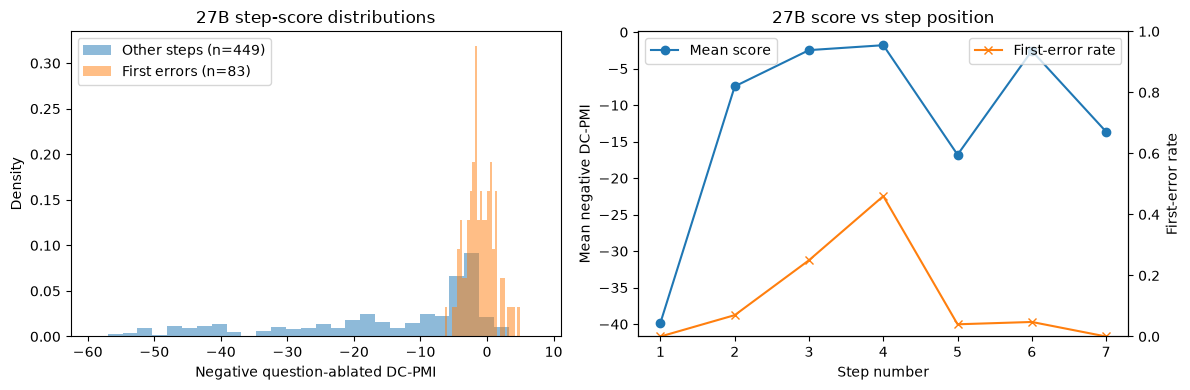

,mean_score,first_error_rate,n_steps
step_number,,,
1,-39.789,0.000,100
2,-7.425,0.070,100
3,-2.458,0.250,100
4,-1.785,0.460,100
5,-16.785,0.040,100
6,-2.553,0.048,21
7,-13.635,0.000,11


In [4]:
scores_27b = scores_by_model['27B'].assign(
    negative_dc_pmi=lambda frame: -frame.dc_pmi_question_ablation,
    step_number=lambda frame: frame.step + 1,
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for is_error, label in ((False, 'Other steps'), (True, 'First errors')):
    group = scores_27b.loc[scores_27b.first_error == is_error]
    axes[0].hist(group.negative_dc_pmi, bins=30, density=True, alpha=0.5, label=f'{label} (n={len(group)})')
axes[0].set(xlabel='Negative question-ablated DC-PMI', ylabel='Density', title='27B step-score distributions')
axes[0].legend()
by_position = scores_27b.groupby('step_number').agg(
    mean_score=('negative_dc_pmi', 'mean'), first_error_rate=('first_error', 'mean'),
    n_steps=('first_error', 'size'),
)
axes[1].plot(by_position.index, by_position.mean_score, marker='o', label='Mean score')
axes[1].set(xlabel='Step number', ylabel='Mean negative DC-PMI', title='27B score vs step position')
ax_rate = axes[1].twinx()
ax_rate.plot(by_position.index, by_position.first_error_rate, marker='x', color='tab:orange',
             label='First-error rate')
ax_rate.set(ylabel='First-error rate', ylim=(0, 1))
axes[1].legend(loc='upper left')
ax_rate.legend(loc='upper right')
plt.tight_layout()
plt.show()
display(by_position.round(3))


## LLM judge comparison

Judge binary F1/MCC measure whether a **trace** contains an error, using parseable answers only. Exact localization accuracy counts unparseable answers as wrong. Neither is directly comparable to the step-level ROC/F1/MCC above.


In [5]:
judge_rows = []
for model, results in judge_by_model.items():
    summary = llm_critic.statistics(results)
    assert len(summary) == 1
    judge_rows.append(summary.iloc[0].to_dict() | {'model': model})
judge_results = pd.DataFrame(judge_rows).set_index('model')
display(judge_results[[
    'n', 'errors', 'unparseable', 'coverage', 'accuracy', 'error_accuracy',
    'no_error_accuracy', 'f1', 'mcc',
]].round(4))
display(pd.DataFrame({
    'negative DC-PMI step AUROC': step_results.xs('Negative question-ablated DC-PMI', level='method').auroc,
    'negative DC-PMI step F1': step_results.xs('Negative question-ablated DC-PMI', level='method').f1,
    'judge trace F1 (parseable)': judge_results.f1,
    'judge exact-location accuracy (all traces)': judge_results.accuracy,
}).round(4))


,n,errors,unparseable,coverage,accuracy,error_accuracy,no_error_accuracy,f1,mcc
model,,,,,,,,,
4B,100,83,0,1.0,0.40,0.2771,1.0000,0.5690,0.3176
9B,100,83,0,1.0,0.39,0.2892,0.8824,0.5593,0.2205
27B,100,83,0,1.0,0.53,0.4578,0.8824,0.6822,0.3109


,negative DC-PMI step AUROC,negative DC-PMI step F1,judge trace F1 (parseable),judge exact-location accuracy (all traces)
model,,,,
4B,0.9074,0.6351,0.5690,0.40
9B,0.8920,0.6410,0.5593,0.39
27B,0.8740,0.5291,0.6822,0.53


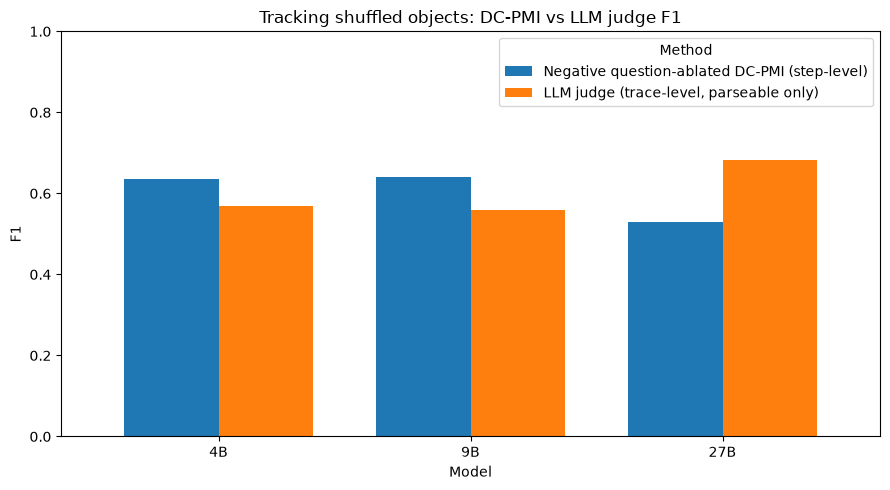

In [6]:
f1_comparison = pd.DataFrame({
    'Negative question-ablated DC-PMI (step-level)':
        step_results.xs('Negative question-ablated DC-PMI', level='method').f1,
    'LLM judge (trace-level, parseable only)': judge_results.f1,
}).reindex(MODELS)
ax = f1_comparison.plot.bar(figsize=(9, 5), rot=0, ylim=(0, 1), width=0.75)
ax.set(xlabel='Model', ylabel='F1', title='Tracking shuffled objects: DC-PMI vs LLM judge F1')
ax.legend(title='Method')
plt.tight_layout()
plt.show()
